### Jack McRae
# Finding the Best Neighborhood in Pittsburgh: Recreation Facilities

I wanted to find which Pittsburgh neighborhood offers the most places to play sports, use a playground, or cool off in the summer. I counted the facilities inside each neighborhood and scored them by category.

## Loading the data

I used the city’s [courts and rinks](https://data.wprdc.org/dataset/city-of-pittsburgh-courts), [playgrounds](https://data.wprdc.org/dataset/playgrounds), and [pools and spray parks](https://data.wprdc.org/dataset/city-pools) files from WPRDC. I also loaded the city’s [neighborhood boundaries](https://data.wprdc.org/dataset/neighborhoods2) to place each facility on the map.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

sources = {
    "Courts and rinks": ("courts_and_rinks.csv", "a5b71bfa-840c-4c86-8f43-07a9ae854227"),
    "Playgrounds": ("playgrounds.csv", "47350364-44a8-4d15-b6e0-5f79ddff9367"),
    "Pools and spray parks": ("pools_and_spray_parks.csv", "5cc254fe-2cbd-4912-9f44-2f95f0beea9a"),
}


def data_source(filename, url):
    for path in (Path("data") / filename, Path(filename)):
        if path.is_file():
            return path
    return url


facilities = {
    category: pd.read_csv(data_source(filename, f"https://data.wprdc.org/datastore/dump/{resource}"),
                          dtype={"id": "string"})
    for category, (filename, resource) in sources.items()
}
boundary_url = (
    "https://data.wprdc.org/dataset/e672f13d-71c4-4a66-8f38-710e75ed80a4/"
    "resource/4af8e160-57e9-4ebf-a501-76ca1b42fc99/download/neighborhoods.geojson"
)
neighborhoods = gpd.read_file(data_source("neighborhoods.geojson", boundary_url))[
    ["hood_no", "hood", "geometry"]
].rename(columns={"hood_no": "neighborhood_id", "hood": "neighborhood"})
neighborhoods["neighborhood"] = neighborhoods["neighborhood"].str.strip()
assert neighborhoods["neighborhood_id"].notna().all()
assert neighborhoods["neighborhood_id"].is_unique
input_totals = pd.Series({category: len(rows) for category, rows in facilities.items()},
                         name="Input records").rename_axis("Dataset")
print(f"Neighborhoods in the boundary file: {len(neighborhoods)}")
display(input_totals.to_frame())

Neighborhoods in the boundary file: 90


,Input records
Dataset,
Courts and rinks,246
Playgrounds,125
Pools and spray parks,28


## Counting facilities by neighborhood

I removed duplicate records and facilities marked inactive. I kept records with unknown activity status and counted each facility only when its coordinates matched one neighborhood. I included all 90 neighborhoods in the count table, with zero for any category that had no match.

In [2]:
coordinate_aliases = {"lat": "latitude", "lon": "longitude", "lng": "longitude"}
status_values = {"t": True, "true": True, "yes": True, "1": True,
                 "f": False, "false": False, "no": False, "0": False}
columns = ["id", "name", "type", "neighborhood", "inactive", "longitude", "latitude"]
cleaned = []

for category, raw in facilities.items():
    rows = raw.rename(columns=lambda column: column.strip().lower()).rename(columns=coordinate_aliases)
    if "name" not in rows:
        for alternate in ("facility_name", "playground_name", "pool_name"):
            if alternate in rows:
                rows = rows.rename(columns={alternate: "name"})
                break
    has_id = "id" in rows
    rows = rows.reindex(columns=columns)
    coords = rows[["longitude", "latitude"]].apply(pd.to_numeric, errors="coerce")
    rows[["longitude", "latitude"]] = coords
    if not has_id:
        names = rows["name"].astype("string").str.strip().str.casefold().replace("", pd.NA)
        rows["id"] = names + "|" + coords["longitude"].astype("string") + "|" + coords["latitude"].astype("string")
    rows["id"] = rows["id"].astype("string").str.strip().replace("", pd.NA)
    rows["inactive"] = rows["inactive"].astype("string").str.strip().str.lower().map(status_values)
    rows = rows.drop_duplicates()
    valid_coords = rows["longitude"].between(-180, 180) & rows["latitude"].between(-90, 90)
    valid_ids = rows["id"].notna() & ~rows["id"].duplicated(keep=False)
    cleaned.append(rows.loc[valid_ids & valid_coords & ~rows["inactive"].eq(True)].assign(category=category))

locations = pd.concat(cleaned, ignore_index=True).drop(columns="neighborhood")
points = gpd.GeoDataFrame(locations, geometry=gpd.points_from_xy(
    locations["longitude"], locations["latitude"]), crs="EPSG:4326")
matches = gpd.sjoin(points.to_crs(neighborhoods.crs), neighborhoods,
                    how="inner", predicate="within")
matches = matches.loc[~matches.duplicated(["category", "id"], keep=False)]
assert set(matches["category"]) == set(facilities)

neighborhood_names = neighborhoods.set_index("neighborhood_id")["neighborhood"]
facility_counts = pd.crosstab(matches["neighborhood_id"], matches["category"]).reindex(
    index=neighborhood_names.index, columns=facilities.keys(), fill_value=0
).rename_axis(columns=None)
print(f"Facilities matched to one neighborhood: {len(matches)}")
print("Example neighborhood counts, ordered by the number of courts and rinks")
display(facility_counts.join(neighborhood_names).set_index("neighborhood")
        .nlargest(3, "Courts and rinks").rename_axis("Neighborhood"))

Facilities matched to one neighborhood: 399
Example neighborhood counts, ordered by the number of courts and rinks


,Courts and rinks,Playgrounds,Pools and spray parks
Neighborhood,,,
Squirrel Hill South,26,8,1
Highland Park,20,4,2
Hazelwood,10,3,1


## Scoring the neighborhoods

I multiplied the square root of each category’s count by its weight and added the points. Courts and rinks and playgrounds have a weight of **2** each, and pools and spray parks have a weight of **3** because they offer a distinct summer activity. The square root gives each additional facility a smaller boost. My earlier two-facility cap gave equal court points to neighborhoods with 2 and 26 facilities.

In [3]:
weights = pd.Series({"Courts and rinks": 2, "Playgrounds": 2, "Pools and spray parks": 3})
category_points = facility_counts.pow(0.5).mul(weights).round(2)
recreation_score = category_points.sum(axis=1).round(2)
rankings = neighborhood_names.to_frame().assign(recreation_score=recreation_score)
rankings["rank"] = recreation_score.rank(method="min", ascending=False).astype(int)
rankings = rankings.sort_values(["rank", "neighborhood"])

top = rankings.join(category_points)
top = top[["rank", "neighborhood", *weights.index, "recreation_score"]]
top.columns = ["Rank", "Neighborhood", "Court/rink pts", "Playground pts", "Pool/spray pts", "Total pts"]
print("Points by category for the five highest-ranked neighborhoods")
display(top.head(5).reset_index(drop=True))

group_scores = rankings[["neighborhood", "recreation_score"]].reset_index()
group_scores["recreation_score_100"] = (
    100 * group_scores["recreation_score"] / category_points.max().sum()
).round(2)

Points by category for the five highest-ranked neighborhoods


,Rank,Neighborhood,Court/rink pts,Playground pts,Pool/spray pts,Total pts
0,1,Squirrel Hill South,10.20,5.66,3.00,18.86
1,2,Highland Park,8.94,4.00,4.24,17.18
2,3,Allegheny Center,6.00,4.00,3.00,13.00
3,3,Beltzhoover,6.00,4.00,3.00,13.00
4,5,Hazelwood,6.32,3.46,3.00,12.78


## Results

Squirrel Hill South finished first with 18.86 points. Its 26 courts and rinks earned 10.20 points, its 8 playgrounds earned 5.66, and its one pool or spray park earned 3.00. The chart shows how those categories contributed to the top scores.

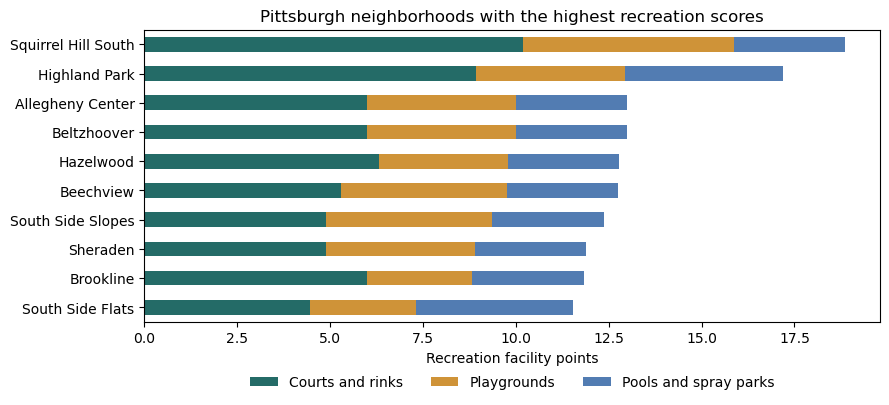

In [4]:
top_names = rankings.loc[rankings["rank"].le(10), "neighborhood"]
chart = category_points.loc[top_names.index].set_index(top_names)
ax = chart.plot.barh(stacked=True, figsize=(9, max(4, 0.42 * len(chart))),
                     color=["#246B67", "#CF9338", "#527CB2"])
ax.invert_yaxis()
ax.set(title="Pittsburgh neighborhoods with the highest recreation scores",
       xlabel="Recreation facility points", ylabel="")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False)
ax.figure.tight_layout()
plt.show()

## Conclusion

My score compares the mix of recreation facilities recorded within each neighborhood. Some records lack activity status, and the courts and playground feeds as frozen since 2021. I also didn't weight ease of access to facilities. Overall, the data gives a good look at each neighborhood and its ammount of recreational facilities. 